In [3]:
import xarray as xr
import warnings
warnings.filterwarnings('ignore')

In [2]:
nwa_data = "/dfs9/hfdrake_hpc/datasets/NWA/NWA12_COBALT_2025_04_bugfixes/gfdl.ncrc6-intel23-prod-hdf5/pp/"
data = "/share/crsp/lab/hfdrake/mariant3/bgcDrought/data/"

In [2]:
# Original monthly model output (surface only)
thetao = xr.open_mfdataset(
    f"{nwa_data}ocean_monthly_z/ts/monthly/5yr/*.thetao.nc"
)["thetao"].isel(z_l=0)

no3 = xr.open_mfdataset(
    f"{nwa_data}ocean_cobalt_tracers_month_z/ts/monthly/5yr/*.no3.nc"
)["no3"].isel(z_l=0)

o2 = xr.open_mfdataset(
    f"{nwa_data}ocean_cobalt_tracers_month_z/ts/monthly/5yr/*.o2.nc"
)["o2"].isel(z_l=0)

chl = xr.open_mfdataset(
    f"{nwa_data}ocean_cobalt_tracers_month_z/ts/monthly/5yr/*.chl.nc"
)["chl"].isel(z_l=0)

dissoc = xr.open_mfdataset(
    f"{nwa_data}ocean_cobalt_tracers_month_z/ts/monthly/5yr/*.dissoc.nc"
)["dissoc"].isel(z_l=0)

dissic = xr.open_mfdataset(
    f"{nwa_data}ocean_cobalt_tracers_month_z/ts/monthly/5yr/*.dissic.nc"
)["dissic"].isel(z_l=0)


# Previously saved monthly thresholds
thetao_p90 = xr.open_dataset(
    f"{data}thetao_monthly_per90_1993-2022.nc"
)["thetao"]

no3_p10 = xr.open_dataset(
    f"{data}no3_monthly_per10_1993-2022.nc"
)["no3"]

o2_p10 = xr.open_dataset(
    f"{data}o2_monthly_per10_1993-2022.nc"
)["o2"]

o2_p90 = xr.open_dataset(
    f"{data}o2_monthly_per90_1993-2022.nc"
)["o2"]

chl_p10 = xr.open_dataset(
    f"{data}chl_monthly_per10_1993-2022.nc"
)["chl"]

chl_p90 = xr.open_dataset(
    f"{data}chl_monthly_per90_1993-2022.nc"
)["chl"]

dissoc_p10 = xr.open_dataset(
    f"{data}dissoc_monthly_per10_1993-2022.nc"
)["dissoc"]

dissoc_p90 = xr.open_dataset(
    f"{data}dissoc_monthly_per90_1993-2022.nc"
)["dissoc"]

dissic_p10 = xr.open_dataset(
    f"{data}dissic_monthly_per10_1993-2022.nc"
)["dissic"]

dissic_p90 = xr.open_dataset(
    f"{data}dissic_monthly_per90_1993-2022.nc"
)["dissic"]

In [50]:
thetao_p90.time.dt.month

<xarray.DataArray 'month' (time: 360)>
array([ 1,  2,  3, ..., 10, 11, 12])
Coordinates:
    quantile  float64 ...
    month     (time) int64 ...
  * time      (time) datetime64[ns] 1993-01-16T12:00:00 ... 2022-12-16T12:00:00
Attributes:
    long_name:      time
    axis:           T
    calendar_type:  GREGORIAN
    bounds:         time_bnds

In [12]:
# mhw = thetao > thetao_p90

In [2]:
mhw = (thetao > thetao_p90).where(thetao.notnull())

In [4]:
mhw

<xarray.DataArray 'thetao' (time: 360, yh: 845, xh: 775)>
dask.array<where, shape=(360, 845, 775), dtype=float64, chunksize=(1, 212, 194), chunktype=numpy.ndarray>
Coordinates:
  * time      (time) datetime64[ns] 1993-01-16T12:00:00 ... 2022-12-16T12:00:00
  * xh        (xh) float64 -98.0 -97.92 -97.84 -97.76 ... -36.24 -36.16 -36.08
  * yh        (yh) float64 5.273 5.352 5.432 5.511 ... 51.88 51.9 51.91 51.93
    z_l       float64 2.5
    quantile  float64 ...
    month     (time) int64 ...

In [5]:
n_years = len(set(thetao.time.dt.year.values))

In [6]:
events_per_year = (mhw == 1).sum("time").where(thetao.isel(time=0).notnull()) / n_years

/data/homezvol3/mariant3/.conda/envs/mhw/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "orientation" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.canvas.print_figure(bytes_io, **kw)
/data/homezvol3/mariant3/.conda/envs/mhw/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "facecolor" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.canvas.print_figure(bytes_io, **kw)
/data/homezvol3/mariant3/.conda/envs/mhw/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "edgecolor" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.canvas.print_figure(bytes_io, **kw)
/data/homezvol3/mariant3/.conda/envs/mhw/lib/py

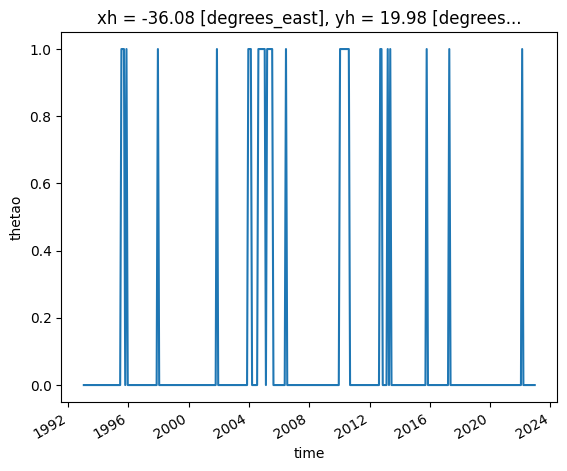

In [19]:
mhw.sel(yh=20, xh=-36, method='nearest').plot()

/data/homezvol3/mariant3/.conda/envs/mhw/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "orientation" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.canvas.print_figure(bytes_io, **kw)
/data/homezvol3/mariant3/.conda/envs/mhw/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "facecolor" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.canvas.print_figure(bytes_io, **kw)
/data/homezvol3/mariant3/.conda/envs/mhw/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "edgecolor" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.canvas.print_figure(bytes_io, **kw)
/data/homezvol3/mariant3/.conda/envs/mhw/lib/py

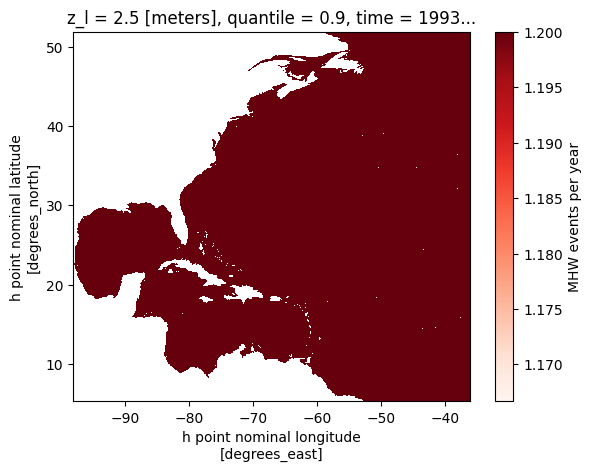

In [7]:
events_per_year.plot(cmap="Reds", cbar_kwargs={"label": "MHW events per year"})

Example frequency with Chl

In [3]:
chl_raw = xr.open_mfdataset(
    f"{nwa_data}ocean_cobalt_tracers_month_z/ts/monthly/5yr/*.chl.nc"
)["chl"].isel(z_l=0, drop=True)

chl = chl_raw.chunk({"time": -1, "yh": 212, "xh": 194})

chl_p10 = (
    xr.open_dataset(
        f"{data}chl_monthly_per10_1993-2022.nc",
        chunks={"time": -1, "yh": 212, "xh": 194},
    )["chl"]
    .squeeze(drop=True)
    .drop_vars("quantile", errors="ignore")
    .sel(time=chl.time)
)

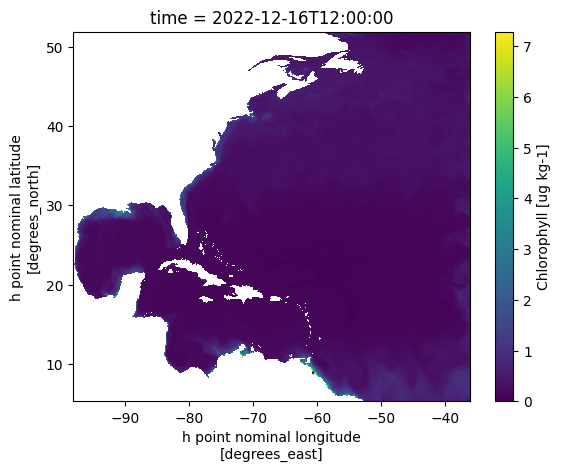

In [6]:
chl_raw.isel(time=-1).plot()

In [15]:
extreme = chl < chl_p10

In [18]:
extreme

<xarray.DataArray 'chl' (time: 360, yh: 845, xh: 775)>
dask.array<lt, shape=(360, 845, 775), dtype=bool, chunksize=(360, 212, 194), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 1993-01-16T12:00:00 ... 2022-12-16T12:00:00
  * xh       (xh) float64 -98.0 -97.92 -97.84 -97.76 ... -36.24 -36.16 -36.08
  * yh       (yh) float64 5.273 5.352 5.432 5.511 ... 51.88 51.9 51.91 51.93
    month    (time) int64 dask.array<chunksize=(360,), meta=np.ndarray>

In [8]:
extreme = chl < chl_p10
mask = chl.isel(time=0, drop=True).notnull()

starts = extreme & ~extreme.shift(time=1, fill_value=False)

freq = (starts.sum("time") / 30).where(mask)
freqy = starts.groupby("time.year").sum().where(mask)

# freq.to_netcdf(f"{data}freq/chl_low_freq.nc")
# freqy.to_netcdf(f"{data}freq/chl_low_freqy.nc")

In [13]:
freq.load()

<xarray.DataArray 'chl' (yh: 845, xh: 775)>
array([[       nan,        nan,        nan, ..., 1.        , 1.        ,
        1.        ],
       [       nan,        nan,        nan, ..., 0.9       , 0.96666667,
        1.        ],
       [       nan,        nan,        nan, ..., 1.        , 1.        ,
        1.06666667],
       ...,
       [       nan,        nan,        nan, ..., 0.96666667, 0.96666667,
        0.9       ],
       [       nan,        nan,        nan, ..., 1.06666667, 1.        ,
        0.96666667],
       [       nan,        nan,        nan, ..., 1.03333333, 1.03333333,
        0.96666667]])
Coordinates:
  * xh       (xh) float64 -98.0 -97.92 -97.84 -97.76 ... -36.24 -36.16 -36.08
  * yh       (yh) float64 5.273 5.352 5.432 5.511 ... 51.88 51.9 51.91 51.93

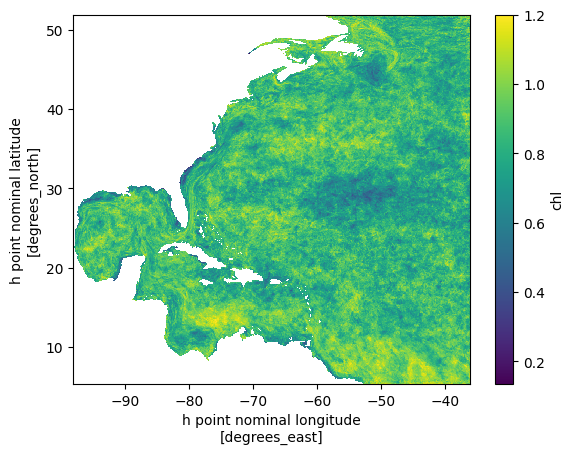

In [14]:
freq.plot()

In [19]:
freqy = freqy.load()

In [21]:
import matplotlib.pyplot as plt

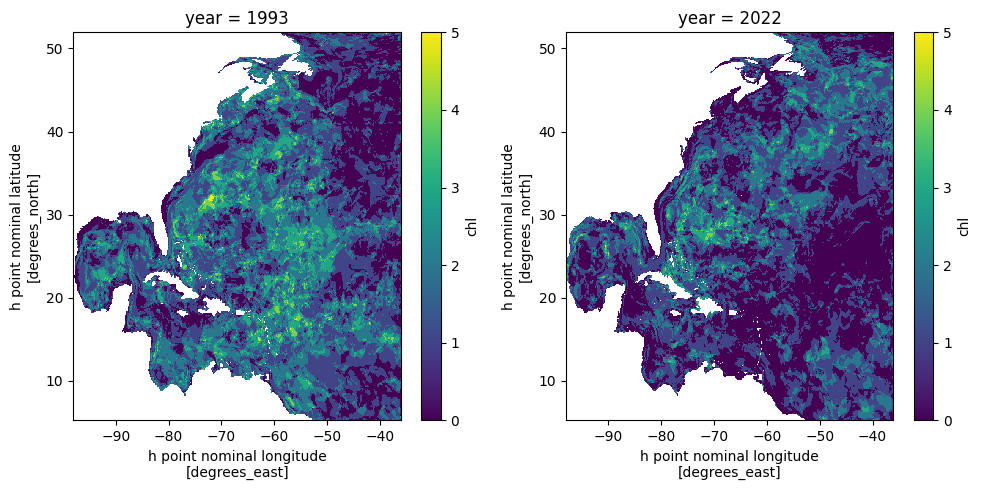

In [23]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
freqy.isel(year=0).plot()
plt.subplot(1, 2, 2)
freqy.isel(year=-1).plot()
plt.tight_layout()
plt.show()